In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from temporal import pipeline_temp

# 1) Features ya extraídos (celda 13) + calibración ya guardada (solo lectura)
df_temporal_abs = pd.read_csv("features_dataset_temporal.csv")
meta = pipeline_temp.load_temporal_score_model("temporal_score_metadata.joblib")

# 2) Score absoluto por imagen (misma lógica que la celda 57)
a, w = meta["population_anchors"], meta["weights"]
df_temporal_abs["absolute_inflammatory_score"] = df_temporal_abs.apply(
    lambda r: pipeline_temp._compute_absolute_inflammatory_score(
        thickness=r["median_thickness"],
        segment_length=r["median_segment_length"],
        ctrl_thickness=a["ctrl_ref"]["median_thickness"],
        inflam_thickness=a["inflam_ref"]["median_thickness"],
        ctrl_segment=a["ctrl_ref"]["median_segment_length"],
        inflam_segment=a["inflam_ref"]["median_segment_length"],
        w_thickness=w["median_thickness"],
        w_segment=w["median_segment_length"],
    ),
    axis=1,
)

In [2]:
print(df_temporal_abs.shape)  # esperado: 64 filas
print(df_temporal_abs.groupby("time_label")["absolute_inflammatory_score"].mean().round(2))
# esperado: 0HS 0.00 | 24HS 33.62 | 48HS 63.50 | 72HS 100.00
print(pipeline_temp.temporal_pairwise_order_accuracy(
    df_temporal_abs, score_col="absolute_inflammatory_score"))
# esperado: correct_pairs 1403 de 1536, ties 21 (exactitud 0.9134)

(64, 33)
time_label
0HS      -0.00
24HS     33.62
48HS     63.50
72HS    100.00
Name: absolute_inflammatory_score, dtype: float64
{'total_pairs': 1536, 'correct_pairs': 1403, 'ties': 21, 'pairwise_order_accuracy': 0.9134114583333334, 'tie_rate': 0.013671875}


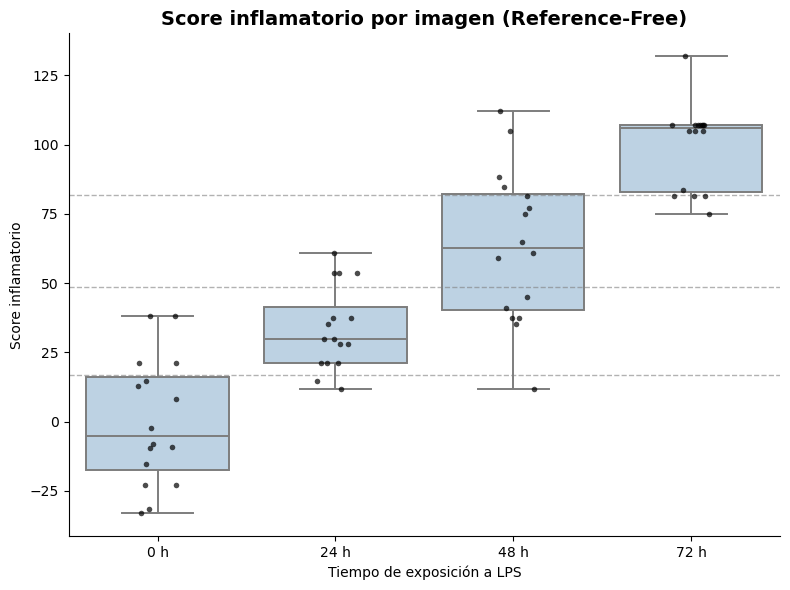

In [3]:
order = ["0HS", "24HS", "48HS", "72HS"]
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_temporal_abs, x="time_label", y="absolute_inflammatory_score",
            order=order, color="#B7D3E9", fliersize=0, linewidth=1.4)
sns.stripplot(data=df_temporal_abs, x="time_label", y="absolute_inflammatory_score",
              order=order, color="black", alpha=0.7, size=4, jitter=0.12)
for thr in meta["thresholds"]:
    plt.axhline(thr, color="gray", linestyle="--", linewidth=1, alpha=0.6)
plt.xticks(range(4), ["0 h", "24 h", "48 h", "72 h"])
plt.xlabel("Tiempo de exposición a LPS")
plt.ylabel("Score inflamatorio")
plt.title("Score inflamatorio por imagen (Reference-Free)", fontsize=14, fontweight="bold")
sns.despine(); plt.tight_layout()
plt.savefig("figura5_boxplot_reference_free.png", dpi=200, bbox_inches="tight")
plt.show()

In [4]:
df_temporal_abs["category"] = df_temporal_abs["absolute_inflammatory_score"].apply(
    lambda s: pipeline_temp.get_progression_category(s, meta["thresholds"]))
pd.crosstab(df_temporal_abs["time_label"], df_temporal_abs["category"])

category,high inflammatory morphology,low inflammatory morphology,mild inflammatory morphology,moderate inflammatory morphology
time_label,,,,
0HS,0,12,4,0
24HS,0,2,10,4
48HS,4,1,5,6
72HS,12,0,0,4


Experiment-Anchored

(64, 33)
time_label  0HS   24HS   48HS   72HS
group                               
N1         -0.0  35.19  74.51  100.0
N2          0.0  37.83  84.73  100.0
N3          0.0  42.45  51.41  100.0
N4          0.0  15.23  45.42  100.0
time_label
0HS       0.00
24HS     32.68
48HS     64.02
72HS    100.00
Name: relative_inflammatory_score, dtype: float64
{'total_pairs': 1536, 'correct_pairs': 1413, 'ties': 5, 'pairwise_order_accuracy': 0.919921875, 'tie_rate': 0.0032552083333333335}


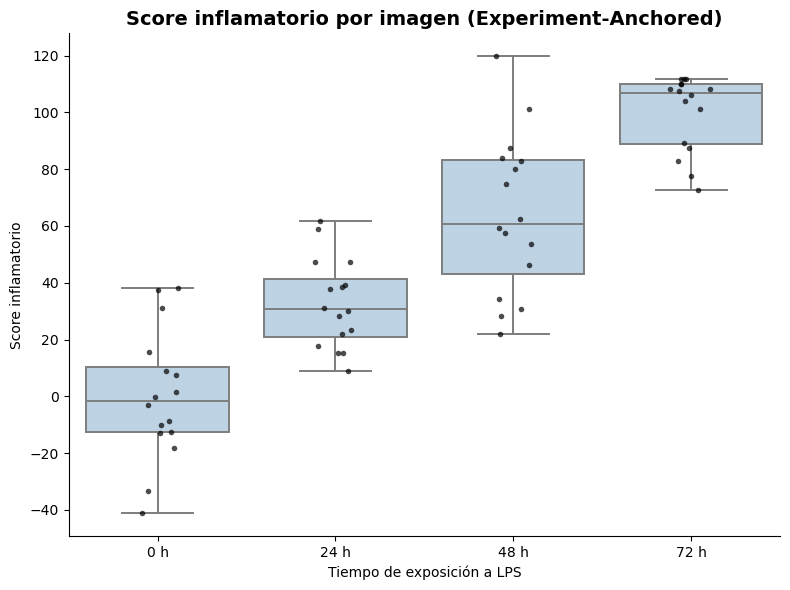

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from temporal import pipeline_temp

# 1) Features ya extraídos (celda 13) + pesos ya guardados (solo lectura)
df_anch = pd.read_csv("features_dataset_temporal.csv")
meta = pipeline_temp.load_temporal_score_model("temporal_score_metadata.joblib")
w = meta["weights"]

# 2) Anclajes de cada cultivo: promedio de SUS imágenes de 0 h (control) y de 72 h (proinflamatoria)
feats = ["median_thickness", "median_segment_length"]
anclas = (
    df_anch[df_anch["time_label"].isin(["0HS", "72HS"])]
    .groupby(["group", "time_label"])[feats].mean()
)

# 3) Score relativo por imagen (misma fórmula que el modo Experiment-Anchored de la app)
def score_anclado(r):
    c = anclas.loc[(r["group"], "0HS")]
    i = anclas.loc[(r["group"], "72HS")]
    return pipeline_temp._compute_absolute_inflammatory_score(
        thickness=r["median_thickness"],
        segment_length=r["median_segment_length"],
        ctrl_thickness=c["median_thickness"],
        inflam_thickness=i["median_thickness"],
        ctrl_segment=c["median_segment_length"],
        inflam_segment=i["median_segment_length"],
        w_thickness=w["median_thickness"],
        w_segment=w["median_segment_length"],
    )

df_anch["relative_inflammatory_score"] = df_anch.apply(score_anclado, axis=1)

# 4) Controles
print(df_anch.shape)  # esperado: 64 filas
print(df_anch.groupby(["group", "time_label"])["relative_inflammatory_score"].mean().unstack()[["0HS","24HS","48HS","72HS"]].round(2))
# esperado: 0HS = 0.00 y 72HS = 100.00 en los cuatro cultivos
# 24HS: N1 35.19 | N2 37.83 | N3 42.45 | N4 15.23
# 48HS: N1 74.51 | N2 84.73 | N3 51.41 | N4 45.42
print(df_anch.groupby("time_label")["relative_inflammatory_score"].mean().round(2))
# esperado: 0HS 0.00 | 24HS 32.68 | 48HS 64.02 | 72HS 100.00
print(pipeline_temp.temporal_pairwise_order_accuracy(
    df_anch, score_col="relative_inflammatory_score"))
# esperado: correct_pairs 1413 de 1536, ties 5 (exactitud 0.9199)

# 5) Figura 6
order = ["0HS", "24HS", "48HS", "72HS"]
plt.figure(figsize=(8, 6))
sns.boxplot(data=df_anch, x="time_label", y="relative_inflammatory_score",
            order=order, color="#B7D3E9", fliersize=0, linewidth=1.4)
sns.stripplot(data=df_anch, x="time_label", y="relative_inflammatory_score",
              order=order, color="black", alpha=0.7, size=4, jitter=0.12)
plt.xticks(range(4), ["0 h", "24 h", "48 h", "72 h"])
plt.xlabel("Tiempo de exposición a LPS")
plt.ylabel("Score inflamatorio")
plt.title("Score inflamatorio por imagen (Experiment-Anchored)", fontsize=14, fontweight="bold")
sns.despine(); plt.tight_layout()
plt.savefig("figura6_boxplot_experiment_anchored.png", dpi=200, bbox_inches="tight")
plt.show()